# Read in Clean Dataset

Import your packages

In [7]:
(0.2341 - 0.2328) / ((0.2328+0.2341)/2) * 100 
(0.1091 - 0.1088) / ((0.1088+0.1091)/2) *100
(0.9131 - 0.9122) / ((0.9122+0.9131)/2) * 100
(216 - 150)/((150+216)/2)*100



36.0655737704918

In [3]:
using Base.Threads
println(nthreads())

4


In [2]:
import Pkg
# This installs only the modern, compatible versions
Pkg.add(["DataFrames", "CSV", "InlineStrings", "Plots",
"Colors","StatsPlots", "Statistics", "XLSX", "Dates", "StatsBase", 
"CategoricalArrays", "Missings", "Chain", "FreqTables", "Glob", "MLJ",
"DecisionTree", "XGBoost", "LoggingExtras", "IJulia", "Parquet2", "OneHotArrays"])


   Resolving package versions...
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`


In [4]:
using DataFrames, CSV, Statistics, Dates, Logging, Parquet2, Glob
using Plots, StatsPlots, DataFrames, StatsBase, Dates, Printf, Colors
using DecisionTree, XGBoost
using Base.Threads
using Printf, StatsBase, Plots, StatsPlots, Statistics
using DecisionTree, XGBoost, Logging
using OneHotArrays

In [5]:
Plots.reset_defaults()
gr()
default(fontfamily="Computer Modern")

Read in your file

In [6]:
filename = "05122026_df_final.parquet"
# Load the parquet file
ds = Parquet2.Dataset(filename)
# Convert it to a DataFrame
df = DataFrame(ds)
stats_df = describe(df, :eltype, :nmissing, :nunique, :min, :max, :median, :mean, :std)



Row,variable,eltype,nmissing,nunique,min,max,median,mean,std
,Symbol,DataType,Int64,Union…,Any,Any,Union…,Union…,Union…
1,award_type_code,String,0,4,A,D,,,
2,awarding_office_code_threeletter,String,0,10,FA0,FA9,,,
3,c8a_program_participant,Bool,0,,false,true,0.0,0.10085,0.301131
4,commercial_item_acquisition_procedures_code,String,0,3,A,Other,,,
5,construction_wage_rate_requirements_code,Bool,0,,false,true,0.0,0.0898637,0.285987
6,contracting_officers_determination_of_business_size_code,Bool,0,,false,true,1.0,0.613876,0.48686
7,corporate_entity_not_tax_exempt,Bool,0,,false,true,1.0,0.615983,0.486363
8,cost_or_pricing_data_code,Bool,0,,false,true,0.0,0.0677948,0.251394
9,dod_claimant_program_code,String,0,25,A1A,S1,,,


In [6]:
vscodedisplay(stats_df)

In [5]:
vscodedisplay(names(df))

In [7]:
shape = size(df)
println("The dataset has $(shape[1]) rows and $(shape[2]) columns.")

The dataset has 429517 rows and 46 columns.


# PLOTS!

Sort the columns

In [ ]:
# 1. Identify all columns
all_cols = names(df)

# 2. Separate the "special" column from the rest
fixed_col = "log_award_amount"
other_cols = filter(c -> c != fixed_col, all_cols)

# 3. Sort the rest alphabetically
sort!(other_cols)

# 4. Combine them: fixed first, then the sorted remainder
new_order = vcat(fixed_col, other_cols)

# 5. Apply the new order to the DataFrame
select!(df, new_order)

stats_df = describe(df, :eltype, :nmissing, :nunique, :min, :max, :median, :mean, :std)
vscodedisplay(stats_df)


In [29]:
import Pkg; Pkg.add("Distributions")

   Resolving package versions...
   Installed Distributions ─ v0.25.125
    Updating `~/.julia/environments/v1.12/Project.toml`
  [31c24e10] + Distributions v0.25.125 [loaded: v0.25.123]
    Updating `~/.julia/environments/v1.12/Manifest.toml`
  [31c24e10] ↑ Distributions v0.25.123 ⇒ v0.25.125 [loaded: v0.25.123]
Precompiling packages...
   2840.0 ms  ✓ Distributions
   1400.6 ms  ✓ Distributions → DistributionsTestExt
   1771.0 ms  ✓ Distributions → DistributionsChainRulesCoreExt
  3 dependencies successfully precompiled in 6 seconds. 448 already precompiled.
  3 dependencies precompiled but different versions are currently loaded. Restart julia to access the new versions. Otherwise, loading dependents of these packages may trigger further precompilation to work with the unexpected versions.


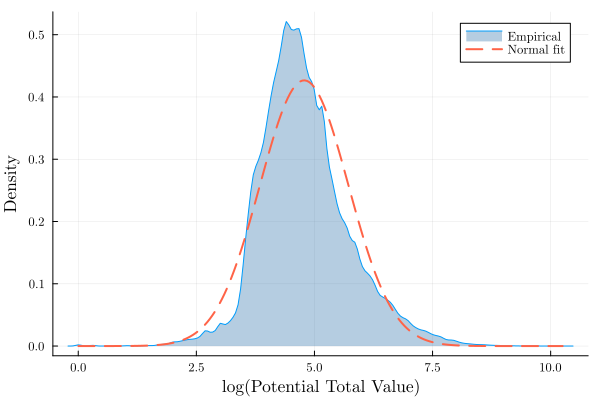

In [32]:
using Distributions
gr()

log_vals = df.log_award_amount

# fit a normal distribution to your data
fitted_normal = fit(Normal, log_vals)

# x range for the overlay
x_range = range(minimum(log_vals), maximum(log_vals), length=200)

# density plot
p = StatsPlots.density(log_vals,
    xlabel = "log(Potential Total Value)",
    ylabel = "Density",
    label = "Empirical",
    fill = (0, 0.4, :steelblue),)

# overlay normal curve
plot!(p, x_range, pdf.(fitted_normal, x_range),
    label = "Normal fit",
    color = :tomato,
    linewidth = 2,
    linestyle = :dash)

In [33]:
savefig(p, "figures/log_award_amount_density_plot.pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/log_award_amount_density_plot.pdf"

# MODEL TIME BB

Phase 1 — Baseline (no tuning)
  - Fit RF with default params, all features, evaluate with 5-fold CV
  - Fit XGB with default params, all features, evaluate with 5-fold CV
  - Record CV RMSE for both → this is your baseline

Phase 2 — Hyperparameter tuning
  - Grid search RF → best RF params → CV RMSE
  - Grid search XGB → best XGB params → CV RMSE
  - Compare tuned RF vs tuned XGB on CV RMSE

Phase 3 — Feature selection (on winning model or both)
  - Permutation importance → adaptive threshold → elbow curve
  - Refit with pruned features → CV RMSE
  - Compare pruned vs full feature model on CV RMSE

Phase 4 — Final evaluation
  - Take the single best model from Phase 3
  - Evaluate once on X_test
  - Report test RMSE, MAE, R²
  - Back-transform: predicted_dollars = 10 .^ predictions

## Phase 0 - Model Prep (splits, encoding, matrix conversion)

In [8]:
# ============================================================
# CONSISTENT RESULT TYPE
# ============================================================

struct ModelResult
    label::String
    rmse::Float64
    rmse_std::Float64
    mae::Float64
    mae_std::Float64
    r2::Float64
    r2_std::Float64
end

# ============================================================
# SCORING HELPER
# ============================================================

function score_predictions(y_true::Vector{Float64}, y_pred::AbstractVector)
    y_pred = Float64.(y_pred)  # convert Float32 to Float64 if needed
    residuals = y_true .- y_pred
    rmse      = sqrt(mean(residuals .^ 2))
    mae       = mean(abs.(residuals))
    ss_res    = sum(residuals .^ 2)
    ss_tot    = sum((y_true .- mean(y_true)) .^ 2)
    r2        = 1 - ss_res / ss_tot
    return rmse, mae, r2
end



score_predictions (generic function with 1 method)

### Split into testing/ training data

In [9]:
# identify categorical columns
categorical_cols = [col for col in names(df) if eltype(df[!, col]) <: Union{AbstractString, Symbol, Bool}]
#show(stdout, MIME"text/plain"(), categorical_cols)
# identify non-categorical columns
numerical_cols = setdiff(names(df), categorical_cols)
#make "solicitation_to_start_date_missing" a categorical colunn
if "solicitation_to_start_date_missing" in numerical_cols
    push!(categorical_cols, "solicitation_to_start_date_missing")
    numerical_cols = setdiff(numerical_cols, ["solicitation_to_start_date_missing"])
end


5-element Vector{String}:
 "number_of_offers_received"
 "performance_start_year"
 "potential_length_of_performance"
 "solicitation_to_start_date"
 "log_award_amount"

In [26]:
# combine(groupby(df, :performance_start_year), 
#     :log_award_amount => mean => :mean_log_award) |> 
#     x -> bar(x.performance_start_year, x.mean_log_award,
#         xlabel = "year",
#         ylabel = "mean log10 award amount",
#         title = "Mean Award Amount by Performance Start Year",
#         label = false,
#         color = :steelblue,
#         alpha = 0.7,
#         size = (800, 400),
#         titlefontweight = :bold,
#         guidefontweight = :bold)

In [10]:
using Random

function stratified_split(df::DataFrame, group_col::Symbol, train_ratio::Float64=0.8, seed::Int=42)
    Random.seed!(seed)
    
    train_idx = Int[]
    test_idx = Int[]
    
    for group in groupby(df, group_col)
        idx = collect(1:nrow(group))
        shuffle!(idx)
        n_train = round(Int, length(idx) * train_ratio)
        append!(train_idx, parentindices(group)[1][idx[1:n_train]])
        append!(test_idx, parentindices(group)[1][idx[n_train+1:end]])
    end
    
    return df[train_idx, :], df[test_idx, :]
end

df_train, df_test = stratified_split(df, :psc_group, 0.8)

println("Train size: $(nrow(df_train))")
println("Test size: $(nrow(df_test))")

# verify stratification held
train_dist = combine(groupby(df_train, :psc_group), nrow => :train_count)
test_dist = combine(groupby(df_test, :psc_group), nrow => :test_count)
println(leftjoin(train_dist, test_dist, on = :psc_group))

Train size: 343613
Test size: 85904
11×3 DataFrame
 Row │ psc_group  train_count  test_count 
     │ String     Int64        Int64?     
─────┼────────────────────────────────────
   1 │ G6               24796        6199
   2 │ G7               30401        7600
   3 │ G4               14028        3507
   4 │ G1               15284        3821
   5 │ G8               17700        4425
   6 │ G5               30538        7635
   7 │ G10              85830       21458
   8 │ Unknown          15864        3966
   9 │ G9               15026        3756
  10 │ G2               60850       15213
  11 │ G3               33296        8324


In [11]:
shape= size(df_train)

(343613, 46)

### ML Prep - target and categorical encoding

In [12]:
# get all categorical cols (you already have this)
cat_cols = [col for col in names(df_train) if 
    eltype(df_train[!, col]) <: Union{AbstractString, Symbol}]

# count unique values for each
cardinality = [(col, length(unique(skipmissing(df_train[!, col])))) 
    for col in cat_cols]
sort!(cardinality, by = x -> x[2])

ohe_cols = [col for (col, n) in cardinality if n <= 20]
target_encode_cols = [col for (col, n) in cardinality if n > 20]
binary_cols = [col for col in names(df_train) if 
    eltype(df_train[!, col]) <: Union{Bool}]
numerical_cols = setdiff(names(df_train), vcat(cat_cols, binary_cols, ohe_cols, target_encode_cols))
push!(binary_cols, "solicitation_to_start_date_missing")


# print them all so you can inspect
#foreach(x -> println(x[2], "\t", x[1]), cardinality)

20-element Vector{String}:
 "c8a_program_participant"
 "construction_wage_rate_requirements_code"
 "contracting_officers_determination_of_business_size_code"
 "corporate_entity_not_tax_exempt"
 "cost_or_pricing_data_code"
 "fed_biz_opps_code"
 "for_profit_organization"
 "historically_underutilized_business_zone_hubzone_firm"
 "labor_standards_code"
 "limited_liability_corporation"
 "manufacturer_of_goods"
 "minority_owned_business"
 "partnership_or_limited_liability_partnership"
 "performance_based_service_acquisition_code"
 "purchase_card_as_payment_method_code"
 "self_certified_small_disadvantaged_business"
 "subchapter_scorporation"
 "veteran_owned_business"
 "woman_owned_business"
 "solicitation_to_start_date_missing"

In [13]:
all_encoded = union(ohe_cols, target_encode_cols, binary_cols, numerical_cols)
all_cols = names(df_train)

println("OHE: ", length(ohe_cols))
println("Target encode: ", length(target_encode_cols))
println("Binary: ", length(binary_cols))
println("Total encoded: ", length(all_encoded))
println("Total df_train cols: ", length(all_cols))

missing_cols = setdiff(all_cols, string.(all_encoded))
extra_cols = setdiff(string.(all_encoded), all_cols)

println("\nColumns in df_train but not in any encoding list: ", missing_cols)
println("Columns in encoding lists but not in df_train: ", extra_cols)

OHE: 18
Target encode: 3
Binary: 20
Total encoded: 46
Total df_train cols: 46

Columns in df_train but not in any encoding list: String[]
Columns in encoding lists but not in df_train: String[]


In [14]:
using CategoricalArrays, Statistics

global_mean = mean(df_train.log_award_amount)

# ── 1. BINARY COLS → INT ──────────────────────────────────────────────────────
for col in binary_cols
    t = eltype(skipmissing(df_train[!, col]))
    if t <: Bool
        df_train[!, col] = Int.(df_train[!, col])
        df_test[!,  col] = Int.(df_test[!,  col])
    elseif t <: AbstractString
        df_train[!, col] = ifelse.(df_train[!, col] .== "Y", 1, 0)
        df_test[!,  col] = ifelse.(df_test[!,  col] .== "Y", 1, 0)
    end
    # already Int → do nothing
end

# ── 2. OHE COLS → SENTINEL + CATEGORICALARRAY ────────────────────────────────
sentinels = ["UNKNOWN", "MISSING_AGENCY_ID", "UNK", ""]
for col in ohe_cols
    levels_train = union(unique(skipmissing(df_train[!, col])), sentinels)
    df_train[!, col] = CategoricalArray(df_train[!, col], levels=levels_train)
    df_test[!,  col] = map(x -> coalesce(x, "UNKNOWN") in Set(levels_train) ? coalesce(x, "UNKNOWN") : "UNKNOWN", df_test[!, col])
    df_test[!,  col] = CategoricalArray(df_test[!, col], levels=levels_train)
end

# ── 3. TARGET ENCODE HIGH CARDINALITY COLS ───────────────────────────────────
for col in target_encode_cols
    col_sym = Symbol(col)
    enc_col = Symbol(string(col) * "_target_enc")
    col_means = combine(groupby(df_train, col_sym),
        :log_award_amount => mean => enc_col)
    leftjoin!(df_train, col_means, on=col_sym)
    leftjoin!(df_test,  col_means, on=col_sym)
    df_train[!, enc_col] = coalesce.(df_train[!, enc_col], global_mean)
    df_test[!,  enc_col] = coalesce.(df_test[!,  enc_col], global_mean)
    select!(df_train, Not(col_sym))
    select!(df_test,  Not(col_sym))
end

# ── 4. VERIFY ─────────────────────────────────────────────────────────────────
println("Train shape: ", size(df_train))
println("Test shape:  ", size(df_test))
println("Any missing in train: ", any(any(ismissing.(df_train[!, col])) for col in names(df_train)))

Train shape: (343613, 46)
Test shape:  (85904, 46)
Any missing in train: false


In [15]:
stats_df = describe(df_train, :eltype, :nmissing, :nunique, :min, :max, :median, :mean, :std)

Row,variable,eltype,nmissing,nunique,min,max,median,mean,std
,Symbol,DataType,Int64,Union…,Any,Any,Union…,Union…,Union…
1,award_type_code,"CategoricalValue{String, UInt32}",0,4,C,A,,,
2,awarding_office_code_threeletter,"CategoricalValue{String, UInt32}",0,10,FA3,FA1,,,
3,c8a_program_participant,Int64,0,,0,1,0.0,0.100808,0.301075
4,commercial_item_acquisition_procedures_code,"CategoricalValue{String, UInt32}",0,3,A,Other,,,
5,construction_wage_rate_requirements_code,Int64,0,,0,1,0.0,0.0899151,0.286061
6,contracting_officers_determination_of_business_size_code,Int64,0,,0,1,1.0,0.613897,0.486855
7,corporate_entity_not_tax_exempt,Int64,0,,0,1,1.0,0.615576,0.486459
8,cost_or_pricing_data_code,Int64,0,,0,1,0.0,0.0676953,0.251223
9,extent_competed_code,"CategoricalValue{String, UInt32}",0,8,A,UNK,,,


### Matrix conversion

In [16]:
using OneHotArrays

function to_matrix(df::DataFrame, target_col::Symbol, ohe_cols::Vector)
    exclude = Set([String(target_col)])
    feature_cols = [c for c in names(df) if !(c in exclude)]
    
    df_encoded = copy(df[!, feature_cols])
    
    for col in names(df_encoded)
        col_data = df_encoded[!, col]
        if nonmissingtype(eltype(col_data)) <: CategoricalArrays.CategoricalValue
            if col in string.(ohe_cols)
                # one hot encode
                lvls = levels(col_data)
                for lvl in lvls
                    df_encoded[!, Symbol(col * "_" * string(lvl))] = Int.(levelcode.(col_data) .== findfirst(==(lvl), lvls))
                end
                select!(df_encoded, Not(col))
            else
                df_encoded[!, col] = levelcode.(col_data)
            end
        end
    end
    
    X = Matrix{Float64}(df_encoded)
    y = Vector{Float64}(df[!, target_col])
    feature_cols_final = names(df_encoded)
    return X, y, feature_cols_final
end

X_train, y_train, feature_cols = to_matrix(df_train, :log_award_amount, ohe_cols)
X_test,  y_test,  _            = to_matrix(df_test,  :log_award_amount, ohe_cols)

println("Train: $(nrow(df_train)) rows | Test: $(nrow(df_test)) rows")
println("Features: $(length(feature_cols))")

Train: 343613 rows | Test: 85904 rows
Features: 216


## Phase 1 - Baseline

In [19]:
function baseline_rf(X_train::Matrix{Float64}, y_train::Vector{Float64},
                     folds::Vector; seed::Int=42,
                     results_path::String="allcol_rf_baseline_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    println("=== RF Baseline ===")
    n_subfeatures = round(Int, sqrt(size(X_train, 2)))
    rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

    for (i, fold) in enumerate(folds)
        model = build_forest(
            y_train[fold.train], X_train[fold.train, :],
            n_subfeatures, 500, 0.7, 15; rng=seed
        )
        rmse, mae, r2 = score_predictions(
            y_train[fold.val],
            apply_forest(model, X_train[fold.val, :])
        )
        push!(rmse_scores, rmse); push!(mae_scores, mae); push!(r2_scores, r2)
        @printf("  Fold %d — RMSE: %.4f | MAE: %.4f | R²: %.4f\n", i, rmse, mae, r2)
    end

    result = ModelResult("RF Baseline",
        mean(rmse_scores), std(rmse_scores),
        mean(mae_scores),  std(mae_scores),
        mean(r2_scores),   std(r2_scores))

    @printf("\n  CV RMSE: %.4f ± %.4f\n", result.rmse, result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n",  result.mae,  result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n",  result.r2,   result.r2_std)

    # save to csv
    df = DataFrame(
        label     = [result.label],
        fold_rmse = [join(round.(rmse_scores, digits=4), ", ")],
        fold_mae  = [join(round.(mae_scores,  digits=4), ", ")],
        fold_r2   = [join(round.(r2_scores,   digits=4), ", ")],
        rmse      = [result.rmse],
        rmse_std  = [result.rmse_std],
        mae       = [result.mae],
        mae_std   = [result.mae_std],
        r2        = [result.r2],
        r2_std    = [result.r2_std],
        timestamp = [string(now())],
        seed      = [seed],
    )
    CSV.write(results_path, df)
    println("  Results saved to $results_path")

    return result
end


function baseline_xgb(X_train::Matrix{Float64}, y_train::Vector{Float64},
                      folds::Vector; seed::Int=42,
                      results_path::String="all_col_xgb_baseline_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    with_logger(NullLogger()) do
    println("\n=== XGBoost Baseline ===")
    rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

    for (i, fold) in enumerate(folds)
        dtrain = DMatrix(X_train[fold.train, :], label=y_train[fold.train])
        model  = xgboost(dtrain;
            num_round=100, max_depth=6, eta=0.1,
            subsample=0.8, colsample_bytree=0.8,
            objective="reg:squarederror", seed=seed)

        rmse, mae, r2 = score_predictions(
            y_train[fold.val],
            XGBoost.predict(model, DMatrix(X_train[fold.val, :]))
        )
        push!(rmse_scores, rmse); push!(mae_scores, mae); push!(r2_scores, r2)
        @printf("  Fold %d — RMSE: %.4f | MAE: %.4f | R²: %.4f\n", i, rmse, mae, r2)
    end

    result = ModelResult("XGB Baseline",
        mean(rmse_scores), std(rmse_scores),
        mean(mae_scores),  std(mae_scores),
        mean(r2_scores),   std(r2_scores))

    @printf("\n  CV RMSE: %.4f ± %.4f\n", result.rmse, result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n",  result.mae,  result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n",  result.r2,   result.r2_std)

    # save to csv
    df = DataFrame(
        label     = [result.label],
        fold_rmse = [join(round.(rmse_scores, digits=4), ", ")],
        fold_mae  = [join(round.(mae_scores,  digits=4), ", ")],
        fold_r2   = [join(round.(r2_scores,   digits=4), ", ")],
        rmse      = [result.rmse],
        rmse_std  = [result.rmse_std],
        mae       = [result.mae],
        mae_std   = [result.mae_std],
        r2        = [result.r2],
        r2_std    = [result.r2_std],
        timestamp = [string(now())],
        seed      = [seed],
    )
    CSV.write(results_path, df)
    println("  Results saved to $results_path")

    return result
    end
end

function make_folds(n::Int; k::Int=5, seed::Int=42)
    Random.seed!(seed)
    fold_idx  = shuffle(1:n)
    fold_size = div(n, k)
    folds = []
    for fold in 1:k
        val_start = (fold - 1) * fold_size + 1
        val_end   = fold == k ? n : fold * fold_size
        val_idx   = fold_idx[val_start:val_end]
        train_idx = setdiff(1:n, val_start:val_end)
        push!(folds, (train=train_idx, val=val_idx))
    end
    return folds
end

make_folds (generic function with 1 method)

### Fit RF and XGB with default params, all features, evaluate with 5-fold CV

In [ ]:
# import XGBoost: predict
# # smoke test on 10% of data
# idx = rand(1:nrow(df_train), 34000)
# X_small = X_train[idx, :]
# y_small = y_train[idx]
# folds = make_folds(size(X_small, 1); k=5, seed=42)


5-element Vector{Any}:
 (train = [6801, 6802, 6803, 6804, 6805, 6806, 6807, 6808, 6809, 6810  …  33991, 33992, 33993, 33994, 33995, 33996, 33997, 33998, 33999, 34000], val = [14326, 4462, 10303, 20174, 27228, 9804, 3468, 33459, 10717, 14870  …  3718, 28224, 27082, 33313, 26241, 3810, 319, 5697, 20341, 17100])
 (train = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  33991, 33992, 33993, 33994, 33995, 33996, 33997, 33998, 33999, 34000], val = [30862, 887, 26522, 16585, 6388, 25051, 20997, 8795, 8717, 13737  …  22315, 32548, 20395, 2946, 30150, 15913, 23176, 4369, 7761, 17044])
 (train = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  33991, 33992, 33993, 33994, 33995, 33996, 33997, 33998, 33999, 34000], val = [19143, 31847, 1515, 26419, 28427, 13936, 8620, 6387, 880, 23689  …  27856, 19004, 10504, 20528, 19255, 27777, 29112, 13128, 26567, 18859])
 (train = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  33991, 33992, 33993, 33994, 33995, 33996, 33997, 33998, 33999, 34000], val = [14356, 13158, 157, 3854, 9692, 6793, 6206, 39

In [ ]:
# rf_baseline_result = baseline_rf(X_small, y_small, folds) # took 54 seconds on 34k rows

=== RF Baseline ===
  Fold 1 — RMSE: 0.7115 | MAE: 0.4790 | R²: 0.5398
  Fold 2 — RMSE: 0.7138 | MAE: 0.4752 | R²: 0.5373
  Fold 3 — RMSE: 0.7132 | MAE: 0.4771 | R²: 0.5291
  Fold 4 — RMSE: 0.7266 | MAE: 0.4775 | R²: 0.5211
  Fold 5 — RMSE: 0.7293 | MAE: 0.4800 | R²: 0.5200

  CV RMSE: 0.7189 ± 0.0084
  CV MAE:  0.4778 ± 0.0019
  CV R²:   0.5295 ± 0.0091
  Results saved to rf_baseline_results.csv


ModelResult("RF Baseline", 0.7188771467456969, 0.00836650366949369, 0.4777663586100651, 0.0018553594199713806, 0.5294690080321992, 0.009060616219778257)

In [ ]:
# xgb_baseline_result = baseline_xgb(X_small, y_small, folds) # took 2 seconds on 34k rows


=== XGBoost Baseline ===
  Fold 1 — RMSE: 0.6560 | MAE: 0.4432 | R²: 0.6088
  Fold 2 — RMSE: 0.6655 | MAE: 0.4425 | R²: 0.5978
  Fold 3 — RMSE: 0.6670 | MAE: 0.4420 | R²: 0.5881
  Fold 4 — RMSE: 0.6866 | MAE: 0.4462 | R²: 0.5723
  Fold 5 — RMSE: 0.6709 | MAE: 0.4445 | R²: 0.5939

  CV RMSE: 0.6692 ± 0.0111
  CV MAE:  0.4436 ± 0.0017
  CV R²:   0.5922 ± 0.0134
  Results saved to xgb_baseline_results.csv


ModelResult("XGB Baseline", 0.6691960329802736, 0.011148467765360395, 0.44364004755931924, 0.0016861186882356036, 0.59218878043191, 0.013421285868498676)

In [20]:
# shared folds — same for both models
folds = make_folds(size(X_train, 1); k=5, seed=42)

RUN_RF_BASELINE  = false
rf_input_file = "allcol_rf_baseline_results_2026-05-12_17-36-24.csv" # set to existing file if you want to skip RF baseline
rf_output_file = "allcol_rf_baseline_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv"
RUN_XGB_BASELINE = false
xgb_input_file = "allcol_xgb_baseline_results_2026-05-12_17-36-24.csv" # set to existing file if you want to skip XGB baseline
xgb_output_file = "allcol_xgb_baseline_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv"


if RUN_RF_BASELINE
    rf_baseline_result = baseline_rf(X_train, y_train, folds)
    CSV.write(rf_output_file, DataFrame(
    label=rf_baseline_result.label, rmse=rf_baseline_result.rmse, rmse_std=rf_baseline_result.rmse_std,
    mae=rf_baseline_result.mae, mae_std=rf_baseline_result.mae_std,
    r2=rf_baseline_result.r2, r2_std=rf_baseline_result.r2_std))
else
    df = CSV.read(rf_input_file, DataFrame)
    rf_baseline_result = ModelResult(df.label[1], df.rmse[1], df.rmse_std[1],
                                                  df.mae[1],  df.mae_std[1],
                                                  df.r2[1],   df.r2_std[1])
    println("=== RF Baseline (loaded from CSV) ===")
    @printf("  CV RMSE: %.4f ± %.4f\n", rf_baseline_result.rmse, rf_baseline_result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n", rf_baseline_result.mae,  rf_baseline_result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n", rf_baseline_result.r2,   rf_baseline_result.r2_std)
end

if RUN_XGB_BASELINE
    xgb_baseline_result = baseline_xgb(X_train, y_train, folds)
    CSV.write(xgb_output_file, DataFrame(
        label=xgb_baseline_result.label, rmse=xgb_baseline_result.rmse, rmse_std=xgb_baseline_result.rmse_std,
        mae=xgb_baseline_result.mae, mae_std=xgb_baseline_result.mae_std,
        r2=xgb_baseline_result.r2, r2_std=xgb_baseline_result.r2_std))
else
    df = CSV.read(xgb_input_file, DataFrame)
    xgb_baseline_result = ModelResult(df.label[1], df.rmse[1], df.rmse_std[1],
                                                   df.mae[1],  df.mae_std[1],
                                                   df.r2[1],   df.r2_std[1])
    println("\n=== XGBoost Baseline (loaded from CSV) ===")
    @printf("  CV RMSE: %.4f ± %.4f\n", xgb_baseline_result.rmse, xgb_baseline_result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n", xgb_baseline_result.mae,  xgb_baseline_result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n", xgb_baseline_result.r2,   xgb_baseline_result.r2_std)
end

=== RF Baseline (loaded from CSV) ===
  CV RMSE: 0.5681 ± 0.0093
  CV MAE:  0.4192 ± 0.0067
  CV R²:   0.6305 ± 0.0125

=== XGBoost Baseline (loaded from CSV) ===
  CV RMSE: 0.5617 ± 0.0074
  CV MAE:  0.4086 ± 0.0056
  CV R²:   0.6388 ± 0.0100


## Phase 2 - Hyperparameter Tuning

### Grid search RF and XGB to find best model hyperparameters

In [21]:
using CSV, DataFrames

function grid_search_rf(X_train::Matrix{Float64}, y_train::Vector{Float64},
                        folds::Vector; seed::Int=42,
                        results_path::String="allcol_rf_grid_search_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    param_grid = [
        (n_trees=100, max_depth=15),
        (n_trees=100, max_depth=20),
        (n_trees=100, max_depth=25),
        (n_trees=100, max_depth=30),
    ]

    n_subfeatures = round(Int, sqrt(size(X_train, 2)))
    results       = Vector{ModelResult}(undef, length(param_grid))

    train_idxs = [fold.train for fold in folds]
    val_idxs   = [fold.val   for fold in folds]

    println("\n=== RF Grid Search ($(length(param_grid)) combos × $(length(folds)) folds) ===\n")

    _X           = X_train::Matrix{Float64}
    _y           = y_train::Vector{Float64}
    _train_idxs  = Vector{Vector{Int}}(train_idxs)
    _val_idxs    = Vector{Vector{Int}}(val_idxs)
    results_lock = ReentrantLock()

    @threads for i in 1:length(param_grid)
        params      = param_grid[i]
        rmse_scores = zeros(length(folds))
        mae_scores  = zeros(length(folds))
        r2_scores   = zeros(length(folds))

        for j in 1:length(folds)
            model = build_forest(
                _y[_train_idxs[j]], _X[_train_idxs[j], :],
                n_subfeatures, params.n_trees, 0.7, params.max_depth; rng=seed
            )
            rmse_scores[j], mae_scores[j], r2_scores[j] = score_predictions(
                _y[_val_idxs[j]],
                apply_forest(model, _X[_val_idxs[j], :])
            )
        end

        label  = "RF d=$(params.max_depth)"
        result = ModelResult(label,
            mean(rmse_scores), std(rmse_scores),
            mean(mae_scores),  std(mae_scores),
            mean(r2_scores),   std(r2_scores))

        lock(results_lock) do
            results[i] = result
            @printf("  %s | RMSE: %.4f ± %.4f | R²: %.4f\n",
                result.label, result.rmse, result.rmse_std, result.r2)
        end
    end

    # save results to csv
    df = DataFrame(
        label    = [r.label    for r in results],
        rmse     = [r.rmse     for r in results],
        rmse_std = [r.rmse_std for r in results],
        mae      = [r.mae      for r in results],
        mae_std  = [r.mae_std  for r in results],
        r2       = [r.r2       for r in results],
        r2_std   = [r.r2_std   for r in results],
        timestamp = string(now()),
        seed      = seed,
    )
    CSV.write(results_path, df)
    println("\n  Results saved to $results_path")

    best_idx    = argmin(r.rmse for r in results)
    best_result = results[best_idx]
    best_params = param_grid[best_idx]

    println("\n  Best: $(best_result.label) | RMSE=$(round(best_result.rmse, digits=4))")
    println("  Refitting on full training set with n_trees=500...")

    best_model = build_forest(
        y_train, X_train, n_subfeatures,
        500, 0.7, best_params.max_depth; rng=seed
    )

    return best_model, best_params, results,
           ModelResult("RF Tuned", best_result.rmse, best_result.rmse_std,
                                   best_result.mae,  best_result.mae_std,
                                   best_result.r2,   best_result.r2_std)
end

function grid_search_xgb(X_train::Matrix{Float64}, y_train::Vector{Float64},
                         folds::Vector; seed::Int=42,
                         results_path::String="allcol_xgb_grid_search_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    with_logger(NullLogger()) do
        
    param_grid = [
    (num_round=500, max_depth=20, eta=0.02, subsample=0.9),
    (num_round=600, max_depth=15, eta=0.02, subsample=0.9),
    (num_round=600, max_depth=20, eta=0.02, subsample=0.9),
    ]
    
    results = Vector{ModelResult}(undef, length(param_grid))

    println("\n=== XGBoost Grid Search ($(length(param_grid)) combos × $(length(folds)) folds) ===\n")

    for i in 1:length(param_grid)
        params      = param_grid[i]
        rmse_scores = zeros(length(folds))
        mae_scores  = zeros(length(folds))
        r2_scores   = zeros(length(folds))

        for (j, fold) in enumerate(folds)
            println("    combo $i/$(length(param_grid)) | fold $j/$(length(folds))...")
            dtrain = DMatrix(X_train[fold.train, :], label=y_train[fold.train])
            dval   = DMatrix(X_train[fold.val, :])
            model  = xgboost(dtrain;
                num_round=params.num_round, max_depth=params.max_depth,
                eta=params.eta, subsample=params.subsample,
                colsample_bytree=0.8, objective="reg:squarederror",
                nthread=Threads.nthreads(),
                seed=seed)

            rmse_scores[j], mae_scores[j], r2_scores[j] = score_predictions(
                y_train[fold.val],
                XGBoost.predict(model, dval)
            )
        end

        label     = "XGB d=$(params.max_depth) r=$(params.num_round)"
        results[i] = ModelResult(label,
            mean(rmse_scores), std(rmse_scores),
            mean(mae_scores),  std(mae_scores),
            mean(r2_scores),   std(r2_scores))

        @printf("  %s | RMSE: %.4f ± %.4f | R²: %.4f\n",
            results[i].label, results[i].rmse, results[i].rmse_std, results[i].r2)
    end

    # save results to csv
    df = DataFrame(
        label     = [r.label     for r in results],
        rmse      = [r.rmse      for r in results],
        rmse_std  = [r.rmse_std  for r in results],
        mae       = [r.mae       for r in results],
        mae_std   = [r.mae_std   for r in results],
        r2        = [r.r2        for r in results],
        r2_std    = [r.r2_std    for r in results],
        timestamp = [string(now()) for _ in results],
        seed      = [seed         for _ in results],
    )
    CSV.write(results_path, df)
    println("\n  Results saved to $results_path")

    best_idx    = argmin(r.rmse for r in results)
    best_result = results[best_idx]
    best_params = param_grid[best_idx]

    println("\n  Best: $(best_result.label) | RMSE=$(round(best_result.rmse, digits=4))")
    println("  Refitting on full training set...")

    dtrain_full = DMatrix(X_train, label=y_train)
    best_model  = xgboost(dtrain_full;
        num_round=best_params.num_round, max_depth=best_params.max_depth,
        eta=best_params.eta, subsample=best_params.subsample,
        colsample_bytree=0.8, objective="reg:squarederror",
        nthread=Threads.nthreads(),
        seed=seed)

    return best_model, best_params, results,
           ModelResult("XGB Tuned", best_result.rmse, best_result.rmse_std,
                                    best_result.mae,  best_result.mae_std,
                                    best_result.r2,   best_result.r2_std)
    end
end

grid_search_xgb (generic function with 1 method)

In [23]:
using Dates, Logging

allcol_xgb_grid_search_results = "allcol_xgb_grid_search_results_2026-05-12_18-10-59.csv"
allcol_rf_grid_search_results  = "allcol_rf_grid_search_results_2026-05-12_17-49-15.csv"

RUN_RF_GRID_SEARCH = false  # set to false after first run
RUN_XGB_GRID_SEARCH = false  # set to false after first run

if RUN_RF_GRID_SEARCH
    rf_model, rf_best_params, rf_cv_results, rf_tuned_result =
        grid_search_rf(X_train, y_train, folds)
else
    # load saved results
    println("\nLoading RF grid search results from CSV...")
    df = CSV.read(allcol_rf_grid_search_results, DataFrame)
    rf_cv_results = [ModelResult(row.label, row.rmse, row.rmse_std,
                                 row.mae,   row.mae_std,
                                 row.r2,    row.r2_std) for row in eachrow(df)]

    best_row    = df[argmin(df.rmse), :]
    best_depth  = parse(Int, match(r"\d+", best_row.label).match)
    rf_best_params = (n_trees=500, max_depth=best_depth)

    n_subfeatures = round(Int, sqrt(size(X_train, 2)))
    rf_model = build_forest(y_train, X_train, n_subfeatures,
                            500, 0.7, best_depth; rng=42);

    rf_tuned_result = ModelResult("RF Tuned", best_row.rmse, best_row.rmse_std,
                                              best_row.mae,  best_row.mae_std,
                                              best_row.r2,   best_row.r2_std)
end


if RUN_XGB_GRID_SEARCH
    println("\nStarting XGBoost grid search...")
    xgb_model, xgb_best_params, xgb_cv_results, xgb_tuned_result =
        grid_search_xgb(X_train, y_train, folds)
else
    println("\nLoading XGBoost grid search results from CSV...")
    df = CSV.read(allcol_xgb_grid_search_results, DataFrame)
    xgb_cv_results = [ModelResult(row.label, row.rmse, row.rmse_std,
                                  row.mae,   row.mae_std,
                                  row.r2,    row.r2_std) for row in eachrow(df)]

    best_row       = df[argmin(df.rmse), :]
    depth_match    = match(r"d=(\d+)", best_row.label)
    round_match    = match(r"r=(\d+)", best_row.label)
    best_depth     = parse(Int, depth_match.match[3:end])
    best_numround  = parse(Int, round_match.match[3:end])
    xgb_best_params = (num_round=best_numround, max_depth=best_depth,
                       eta=0.01, subsample=0.9)

    dtrain_full = DMatrix(X_train, label=y_train)
    xgb_model   = xgboost(dtrain_full;
        num_round=xgb_best_params.num_round, max_depth=xgb_best_params.max_depth,
        eta=xgb_best_params.eta, subsample=xgb_best_params.subsample,
        colsample_bytree=0.8, objective="reg:squarederror", seed=42);

    xgb_tuned_result = ModelResult("XGB Tuned", best_row.rmse, best_row.rmse_std,
                                                best_row.mae,  best_row.mae_std,
                                                best_row.r2,   best_row.r2_std)
end


Loading XGBoost grid search results from CSV...


┌ Info: XGBoost: starting training.
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:601
┌ Info: [1]	train-rmse:0.92785160023944691
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [2]	train-rmse:0.92117082596358246
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [3]	train-rmse:0.91447087648378256
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [4]	train-rmse:0.90842387749217890
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [5]	train-rmse:0.90188193505606351
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [6]	train-rmse:0.89617223776389565
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [7]	train-rmse:0.89058621470509891
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [8]	train-rmse:0.88427671685283049
└ @ XGBoost /Users/paola/.ju

ModelResult("XGB Tuned", 0.2988868063035846, 0.03815854777611734, 0.16508269887627733, 0.015158042130359914, 0.8963856151363991, 0.026297020775972176)

In [66]:
# current best as of this run
xgb_best_so_far = (num_round=600, max_depth=25, eta=0.03, subsample=0.9)
# RMSE: 0.6525 | R²: 0.5105

(num_round = 600, max_depth = 25, eta = 0.03, subsample = 0.9)

### Compare Tuned RF vs Tuned XGB on CV RMSE

In [24]:
# summary table
println("\n=== PHASE 1 vs PHASE 2 SUMMARY (CV RMSE) ===")
@printf("%-25s %-10s\n", "Model", "CV RMSE")
println("-"^35)
@printf("%-25s %.4f\n", "RF Baseline",    rf_baseline_result.rmse)
@printf("%-25s %.4f\n", "RF Tuned",       minimum(r.rmse for r in rf_cv_results))
@printf("%-25s %.4f\n", "XGBoost Baseline", xgb_baseline_result.rmse)
@printf("%-25s %.4f\n", "XGBoost Tuned",  minimum(r.rmse for r in xgb_cv_results))


=== PHASE 1 vs PHASE 2 SUMMARY (CV RMSE) ===
Model                     CV RMSE   
-----------------------------------
RF Baseline               0.5681
RF Tuned                  0.4772
XGBoost Baseline          0.5617
XGBoost Tuned             0.2989


In [46]:
import Pkg; Pkg.add("LaTeXStrings")

   Resolving package versions...
    Updating `~/.julia/environments/v1.12/Project.toml`
  [b964fa9f] + LaTeXStrings v1.4.0
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`


In [34]:
using LaTeXStrings
function plot_model_comparison(results::Vector{ModelResult})
    labels    = [r.label for r in results]
    rmse_vals = [r.rmse  for r in results]
    rmse_stds = [r.rmse_std for r in results]
    mae_vals  = [r.mae   for r in results]
    r2_vals   = [r.r2    for r in results]
    mae_stds = [r.mae_std for r in results]
    r2_stds  = [r.r2_std  for r in results]

    # color by model family
    colors = [occursin("RF", r.label) ? :steelblue : :tomato for r in results]
    alphas = [occursin("Baseline", r.label) ? 0.5 : 1.0 for r in results]

    p1 = bar(labels, rmse_vals,
        yerror    = rmse_stds,
        #title     = "Cross-Validated RMSE",
        ylabel    = "RMSE (log)",
        label     = false,
        color     = colors,
        alpha     = alphas,
        xrotation = 20,
        ylims     = (0, maximum(rmse_vals) * 1.2)
    )
    annotate!(p1, [(i-0.5, rmse_vals[i] + rmse_stds[i] + 0.02,
        text(string(round(rmse_vals[i], digits=4)), font(8, "Computer Modern"), :center)) for i in 1:length(results)])

    p2 = bar(labels, mae_vals,
        #title     = "CV MAE",
        yerror    = mae_stds,
        ylabel    = "MAE (log)",
        label     = false,
        color     = colors,
        alpha     = alphas,
        xrotation = 20,
        ylims     = (0, maximum(mae_vals) * 1.2)
    )
    annotate!(p2, [(i-0.5, mae_vals[i] + mae_stds[i] + 0.02,
        text(string(round(mae_vals[i], digits=4)), font(8, "Computer Modern"), :center)) for i in 1:length(results)])

    p3 = bar(labels, r2_vals,
        #title     = L"CV $R^2$",
        yerror    = r2_stds,
        ylabel    = L"$R^2$",
        label     = false,
        color     = colors,
        alpha     = alphas,
        xrotation = 20,
        ylims     = (0, 1.05)
    )
        annotate!(p3, [(i-0.5, r2_vals[i] + r2_stds[i] + 0.04,
        text(string(round(r2_vals[i], digits=4)), font(8, "Computer Modern"), :center)) for i in 1:length(results)])

    plot(p1, p2, p3, layout=(1, 3), size=(1100, 420), 
        left_margin=10Plots.mm, top_margin=1Plots.mm,
        bottom_margin=10Plots.mm, right_margin=5Plots.mm)

end
# plot baseline vs tuned for both models
# p = plot_model_comparison([rf_baseline_result, rf_tuned_result, xgb_baseline_result, xgb_tuned_result])

plot_model_comparison (generic function with 1 method)

In [59]:
savefig(p, "figures/CV_performance_rf_xgb.pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/CV_performance_rf_xgb.pdf"

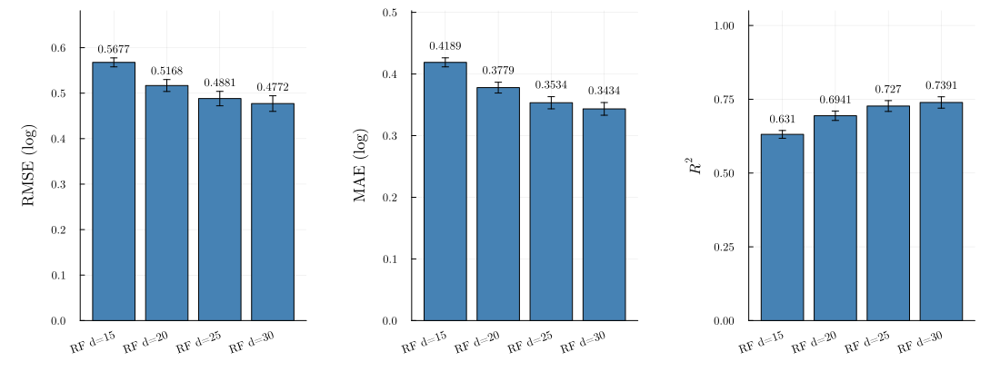

In [60]:
plot_model_comparison(rf_cv_results)

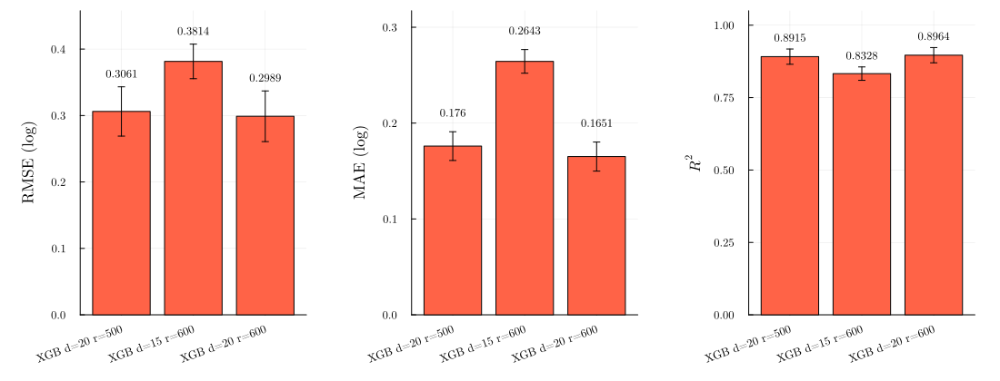

In [61]:
plot_model_comparison(xgb_cv_results)

## Phase 3 - Feature Selection on Winning Model

In [25]:
# determine winner from phase 2
winner_type   = rf_tuned_result.rmse <= xgb_tuned_result.rmse ? :rf : :xgb
winner_model  = winner_type == :rf ? rf_model : xgb_model
winner_tuned  = winner_type == :rf ? rf_tuned_result : xgb_tuned_result
winner_params_rf  = winner_type == :rf ? rf_best_params : nothing
winner_params_xgb = winner_type == :xgb ? xgb_best_params : nothing

println("Phase 2 winner: $(winner_tuned.label)")



Phase 2 winner: XGB Tuned


In [26]:
# validation slice from train for permutation importance
val_cut = round(Int, size(X_train, 1) * 0.8);
X_val   = X_train[val_cut+1:end, :];
y_val   = y_train[val_cut+1:end];

### Permutation importance, Adaptive Threshold, and Elbow Curve

In [27]:
function permutation_importance(model, model_type::Symbol,
                                X::Matrix{Float64}, y::Vector{Float64},
                                feature_cols::Vector;
                                n_repeats::Int=5, seed::Int=42,
                                subsample::Int=50_000)
    Random.seed!(seed)

    # subsample for speed
    n   = length(y)
    idx = n <= subsample ? (1:n) : randperm(n)[1:subsample]
    X   = X[idx, :]
    y   = y[idx]

    # drop near-zero variance features
    active_mask = [std(X[:, j]) > 1e-6 for j in 1:size(X, 2)]
    active_idxs = findall(active_mask)
    println("  Active features: $(length(active_idxs)) / $(length(feature_cols)) (dropped $(sum(.!active_mask)) zero-variance)")

    # baseline
    if model_type == :rf
        baseline_preds = apply_forest(model, X)
    elseif model_type == :xgb
        baseline_preds = XGBoost.predict(model, DMatrix(X))
    end
    baseline_rmse = sqrt(mean((y .- baseline_preds) .^ 2))
    println("  Baseline RMSE: $(round(baseline_rmse, digits=4))")
    println("  Running $(length(active_idxs)) features × $n_repeats repeats on $(length(y)) rows...\n")

    importances = zeros(length(feature_cols))
    X_perm      = copy(X)  # one copy, reused across all features

    for j in active_idxs
        original_col = copy(X[:, j])
        fold_rmses   = zeros(n_repeats)

        for r in 1:n_repeats
            X_perm[:, j] = shuffle(original_col)
            if model_type == :rf
                fold_rmses[r] = sqrt(mean((y .- apply_forest(model, X_perm)) .^ 2))
            elseif model_type == :xgb
                fold_rmses[r] = sqrt(mean((y .- XGBoost.predict(model, DMatrix(X_perm))) .^ 2))
            end
        end

        X_perm[:, j]  = original_col
        importances[j] = mean(fold_rmses) - baseline_rmse
        println("  ✓ $(rpad(string(feature_cols[j]), 35)) importance: $(round(importances[j], digits=4))")
    end

    imp_df = DataFrame(
        feature                = string.(feature_cols),
        permutation_importance = importances
    )
    sort!(imp_df, :permutation_importance, rev=true)
    return imp_df
end
function adaptive_threshold(imp_df::DataFrame)
    vals      = imp_df.permutation_importance
    pos_vals  = vals[vals .> 0]
    μ         = mean(pos_vals)
    σ         = std(pos_vals)
    threshold = μ + σ

    total     = sum(pos_vals)
    imp_df[!, :cumulative_pct] = cumsum(max.(vals, 0) ./ total .* 100)

    println("\n=== Adaptive Threshold (μ + 0.5σ = $(round(threshold, digits=4))) ===")
    println(@sprintf("%-35s %-12s %-12s %s", "FEATURE", "IMPORTANCE", "CUMUL %", ""))
    println("-"^70)
    for row in eachrow(imp_df)
        marker = row.permutation_importance >= threshold ? " ◀ keep" : ""
        @printf("%-35s %-12.4f %-12.1f%%%s\n",
            row.feature, row.permutation_importance, row.cumulative_pct, marker)
    end

    kept = imp_df[imp_df.permutation_importance .>= threshold, :]
    @printf("\nFeatures kept: %d / %d\n", nrow(kept), nrow(imp_df))
    return kept, threshold
end
function optimize_feature_count(X_train::Matrix{Float64}, y_train::Vector{Float64},
                                 folds::Vector, imp_df::DataFrame,
                                 feature_cols::Vector, model_type::Symbol;
                                 seed::Int=42,
                                 # best params from phase 2
                                 rf_params=nothing, xgb_params=nothing)
    with_logger(NullLogger()) do
    sorted_features = imp_df.feature
    max_n           = length(sorted_features)
    results_log     = DataFrame(n_features=Int[], rmse=Float64[], std=Float64[])

    println("\n=== Elbow Curve — Feature Count Optimization ===")

    for n in 1:max_n
        current_cols = [findfirst(==(f), string.(feature_cols)) for f in sorted_features[1:n]]
        rmse_scores  = Float64[]

        for fold in folds
            X_tr = X_train[fold.train, current_cols]
            X_vl = X_train[fold.val,   current_cols]
            y_tr = y_train[fold.train]
            y_vl = y_train[fold.val]

            if model_type == :rf
                p = rf_params
                model = build_forest(y_tr, X_tr,
                    round(Int, sqrt(n)),
                    500, 0.7, p.max_depth; rng=seed)
                preds = apply_forest(model, X_vl)
            elseif model_type == :xgb
                p     = xgb_params
                model = xgboost(DMatrix(X_tr, label=y_tr);
                    num_round=p.num_round, max_depth=p.max_depth,
                    eta=p.eta, subsample=p.subsample,
                    colsample_bytree=0.8,
                    objective="reg:squarederror",
                    seed=seed)
                preds = XGBoost.predict(model, DMatrix(X_vl))
            end

            push!(rmse_scores, sqrt(mean((y_vl .- preds) .^ 2)))
        end

        mean_rmse = mean(rmse_scores)
        std_rmse  = std(rmse_scores)
        push!(results_log, (n, mean_rmse, std_rmse))
        @printf("  Top %2d features | RMSE: %.4f ± %.4f\n", n, mean_rmse, std_rmse)
    end

    best_n   = results_log[argmin(results_log.rmse), :n_features]
    best_rmse = minimum(results_log.rmse)
    println("\n  Optimal feature count: $best_n | RMSE: $(round(best_rmse, digits=4))")

    # elbow plot
    p = plot(results_log.n_features, results_log.rmse,
        ribbon     = results_log.std,
        fillalpha  = 0.2,
        xlabel     = "Number of Features",
        ylabel     = "RMSE (log scale)",
        #title      = "Elbow Curve — Feature Count vs RMSE",
        label      = "CV RMSE",
        marker     = :circle,
        color      = :steelblue,
        linewidth  = 2,
        size       = (700, 400)
    )
    vline!(p, [best_n],
        label     = "optimal n=$(best_n)",
        color     = :tomato,
        linestyle = :dash,
        linewidth = 2)
    display(p)

        # at the end of the function before return
    savefig(p, "figures/elbow_curve_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).pdf")
    display(p)

    return best_n, results_log
    end
end

optimize_feature_count (generic function with 1 method)

In [28]:
function _run_feature_sweep(ns::Vector{Int},
                             sorted_features::Vector,
                             feature_cols::Vector,
                             X_train::Matrix{Float64},
                             y_train::Vector{Float64},
                             folds::Vector;
                             model_type::Symbol,
                             seed::Int,
                             rf_params=nothing,
                             xgb_params=nothing,
                             xgb_round_cap::Int=100)

    results = DataFrame(n_features=Int[], rmse=Float64[], std=Float64[])

    for n in ns
        current_cols = [findfirst(==(f), string.(feature_cols)) for f in sorted_features[1:n]]
        filter!(!isnothing, current_cols)   # guard against unmatched names
        rmse_scores  = Float64[]

        for fold in folds
            X_tr = X_train[fold.train, current_cols]
            X_vl = X_train[fold.val,   current_cols]
            y_tr = y_train[fold.train]
            y_vl = y_train[fold.val]

            if model_type == :rf
                p     = rf_params
                model = build_forest(y_tr, X_tr,
                            round(Int, sqrt(n)),
                            500, 0.7, p.max_depth; rng=seed)
                preds = apply_forest(model, X_vl)

            elseif model_type == :xgb
                p            = xgb_params
                sweep_rounds = min(p.num_round, xgb_round_cap)
                model        = xgboost(DMatrix(X_tr, label=y_tr);
                                   num_round          = sweep_rounds,
                                   max_depth          = p.max_depth,
                                   eta                = p.eta,
                                   subsample          = p.subsample,
                                   colsample_bytree   = 0.8,
                                   objective          = "reg:squarederror",
                                   seed               = seed)
                preds = XGBoost.predict(model, DMatrix(X_vl))
            end

            push!(rmse_scores, sqrt(mean((y_vl .- preds) .^ 2)))
        end

        μ, σ = mean(rmse_scores), std(rmse_scores)
        push!(results, (n, μ, σ))
        @printf("  Top %3d features | RMSE: %.4f ± %.4f\n", n, μ, σ)
    end

    return results
end


function optimize_feature_count(X_train::Matrix{Float64},
                                 y_train::Vector{Float64},
                                 folds::Vector,
                                 imp_df::DataFrame,
                                 feature_cols::Vector,
                                 model_type::Symbol;
                                 seed::Int       = 42,
                                 coarse_step::Int = 10,
                                 xgb_round_cap::Int = 100,
                                 rf_params        = nothing,
                                 xgb_params       = nothing)

    with_logger(NullLogger()) do

    sorted_features = imp_df.feature
    max_n           = length(sorted_features)

    sweep_kwargs = (; model_type, seed, rf_params, xgb_params, xgb_round_cap)

    # ── Coarse pass ──────────────────────────────────────────────────────────
    coarse_ns = unique(vcat(1:2, coarse_step:coarse_step:max_n, max_n))
    println("\n=== Elbow Curve — Coarse Pass (step=$coarse_step, $(length(coarse_ns)) points) ===")

    results_log = _run_feature_sweep(coarse_ns, sorted_features, feature_cols,
                                      X_train, y_train, folds; sweep_kwargs...)

    coarse_best_n = results_log[argmin(results_log.rmse), :n_features]
    println("\n  Coarse best: n=$coarse_best_n | RMSE: $(round(minimum(results_log.rmse), digits=4))")

    # ── Fine pass: ±coarse_step window around coarse best ────────────────────
    fine_range = max(1, coarse_best_n - coarse_step + 1) : min(max_n, coarse_best_n + coarse_step - 1)
    fine_ns    = filter(n -> n ∉ results_log.n_features, collect(fine_range))

    if !isempty(fine_ns)
        println("\n=== Fine Pass (n=$(first(fine_range))–$(last(fine_range)), $(length(fine_ns)) new points) ===")
        fine_log = _run_feature_sweep(fine_ns, sorted_features, feature_cols,
                                       X_train, y_train, folds; sweep_kwargs...)
        append!(results_log, fine_log)
        sort!(results_log, :n_features)
    end

    # ── Result ───────────────────────────────────────────────────────────────
    best_n    = results_log[argmin(results_log.rmse), :n_features]
    best_rmse = minimum(results_log.rmse)
    println("\n  ✓ Optimal feature count: $best_n | RMSE: $(round(best_rmse, digits=4))")

    # ── Plot ─────────────────────────────────────────────────────────────────
    p = plot(results_log.n_features, results_log.rmse,
        ribbon    = results_log.std,
        fillalpha = 0.2,
        xlabel    = "Number of Features",
        ylabel    = "RMSE",
        label     = "CV RMSE",
        marker    = :circle,
        color     = :steelblue,
        linewidth = 2,
        size      = (700, 400))
    vline!(p, [best_n],
        label     = "optimal n=$best_n",
        color     = :tomato,
        linestyle = :dash,
        linewidth = 2)

    savefig(p, "figures/elbow_curve_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).pdf")
    display(p)

    return best_n, results_log
    end
end

optimize_feature_count (generic function with 1 method)

Permutation importance loaded from CSV.
Adaptive threshold loaded from CSV.

Running elbow curve...

=== Elbow Curve — Coarse Pass (step=10, 24 points) ===
  Top   1 features | RMSE: 0.7843 ± 0.0038
  Top   2 features | RMSE: 0.7885 ± 0.0038
  Top  10 features | RMSE: 0.6190 ± 0.0104
  Top  20 features | RMSE: 0.5693 ± 0.0123
  Top  30 features | RMSE: 0.5521 ± 0.0131
  Top  40 features | RMSE: 0.5461 ± 0.0127
  Top  50 features | RMSE: 0.5458 ± 0.0118
  Top  60 features | RMSE: 0.5432 ± 0.0125
  Top  70 features | RMSE: 0.5442 ± 0.0125
  Top  80 features | RMSE: 0.5433 ± 0.0121
  Top  90 features | RMSE: 0.5443 ± 0.0120
  Top 100 features | RMSE: 0.5453 ± 0.0118
  Top 110 features | RMSE: 0.5464 ± 0.0115
  Top 120 features | RMSE: 0.5436 ± 0.0115
  Top 130 features | RMSE: 0.5451 ± 0.0117
  Top 140 features | RMSE: 0.5452 ± 0.0114
  Top 150 features | RMSE: 0.5435 ± 0.0115
  Top 160 features | RMSE: 0.5469 ± 0.0118
  Top 170 features | RMSE: 0.5464 ± 0.0117
  Top 180 features | RMSE: 

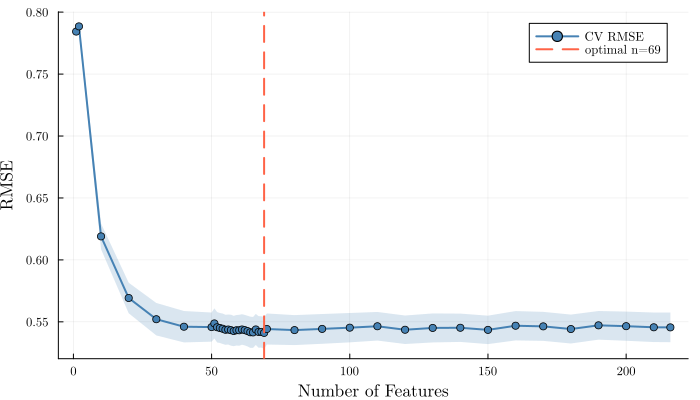

"elbow_curve_results_2026-05-12_23-08-25.csv"

In [30]:
RUN_PERMUTATION_IMPORTANCE = false
perm_imp_path = "permutation_importance_results_2026-05-12_20-53-42.csv"

RUN_ADAPTIVE_THRESHOLD     = false
adaptive_threshold_path = "adaptive_threshold_results_2026-05-12_20-53-43.csv"

RUN_ELBOW_CURVE            = true
#elbow_curve_path = "elbow_curve_results_2026-05-07_17-11-45.csv"

if RUN_PERMUTATION_IMPORTANCE
    println("\nRunning permutation importance...")
    imp_df = permutation_importance(winner_model, winner_type, X_val, y_val, feature_cols)
    CSV.write("permutation_importance_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", imp_df)
    # step 1 — permutation importance
else
    imp_df = CSV.read(perm_imp_path, DataFrame)
    println("Permutation importance loaded from CSV.")
end

if RUN_ADAPTIVE_THRESHOLD
    println("\nRunning adaptive threshold...")
    kept_features, threshold = adaptive_threshold(imp_df)
    CSV.write("adaptive_threshold_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", kept_features)
else
    kept_features = CSV.read(adaptive_threshold_path, DataFrame)
    threshold = mean(kept_features.permutation_importance) # or hardcode it
    println("Adaptive threshold loaded from CSV.")
end

if RUN_ELBOW_CURVE
    println("\nRunning elbow curve...")
    best_n, elbow_results = optimize_feature_count(
    X_train, y_train,
    folds,
    imp_df,              # output from adaptive_threshold — the kept features df
    feature_cols,        # your full feature column vector
    :xgb;               # or :rf
    seed        = 42,
    coarse_step = 10,
    xgb_round_cap = 100,
    xgb_params  = xgb_best_params   # your named tuple from grid search
)

    # best_n, elbow_results = optimize_feature_count(
    #     X_train, y_train, folds, smol_imp_df, feature_cols, winner_type;
    #     rf_params=winner_params_rf, xgb_params=winner_params_xgb, seed=42)
    #     #save results with todays date and time
    CSV.write("elbow_curve_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", elbow_results)
    #savefig("elbow_curve_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).png")
else
    elbow_results = CSV.read(elbow_curve_path, DataFrame)
    best_n        = elbow_results[argmin(elbow_results.rmse), :n_features]
    println("Elbow curve loaded from CSV. Best n=$best_n")

    # rebuild plot from saved results
    plt = plot(elbow_results.n_features, elbow_results.rmse,
        ribbon    = elbow_results.std,
        fillalpha = 0.2,
        xlabel    = "Number of Features",
        ylabel    = "RMSE (log)",
        #title     = "Feature Count vs RMSE",
        label     = "CV RMSE",
        marker    = :circle,
        color     = :mediumseagreen,
        linewidth = 2,
        size      = (700, 400)
    )
    vline!(plt, [best_n],
        label     = "optimal n=$(best_n)",
        color     = :deeppink,
        linestyle = :dash,
        linewidth = 2)
    display(plt)
end

In [71]:
smol_imp_df = imp_df[1:134, :]

Row,feature,permutation_importance,cumulative_pct
,String,Float64,Float64
1,potential_length_of_performance,0.519222,19.4451
2,solicitation_to_start_date_missing,0.245169,28.6268
3,performance_start_year,0.196606,35.9898
4,number_of_offers_received,0.110719,40.1363
5,naics_code_sector_target_enc,0.0830803,43.2477
6,fed_biz_opps_code,0.0802753,46.2541
7,dod_claimant_program_code_target_enc,0.0666646,48.7507
8,commercial_item_acquisition_procedures_code_D,0.0633956,51.1249
9,solicitation_to_start_date,0.0562834,53.2327


In [69]:
kept_features

Row,feature,permutation_importance,cumulative_pct
,String,Float64,Float64
1,potential_length_of_performance,0.519222,19.4451
2,solicitation_to_start_date_missing,0.245169,28.6268
3,performance_start_year,0.196606,35.9898
4,number_of_offers_received,0.110719,40.1363
5,naics_code_sector_target_enc,0.0830803,43.2477
6,fed_biz_opps_code,0.0802753,46.2541
7,dod_claimant_program_code_target_enc,0.0666646,48.7507
8,commercial_item_acquisition_procedures_code_D,0.0633956,51.1249
9,solicitation_to_start_date,0.0562834,53.2327


In [31]:
top_features  = imp_df.feature[1:best_n]
top_col_idxs  = [findfirst(==(f), string.(feature_cols)) for f in top_features]
X_train_final = X_train[:, top_col_idxs]
X_test_final  = X_test[:,  top_col_idxs]

85904×69 Matrix{Float64}:
    8.0  1.0  2025.0   1.0  5.11191  …  0.0  0.0  0.0  0.0  0.0  0.0  0.0
  368.0  0.0  2019.0   0.0  5.32495     0.0  1.0  0.0  0.0  1.0  0.0  0.0
 1826.0  0.0  2019.0   8.0  5.32495     1.0  1.0  0.0  0.0  1.0  0.0  1.0
  365.0  1.0  2019.0   1.0  4.62309     0.0  0.0  0.0  0.0  0.0  0.0  0.0
   52.0  1.0  2016.0   8.0  4.85335     0.0  1.0  0.0  0.0  1.0  0.0  0.0
  729.0  0.0  2025.0   1.0  5.32495  …  1.0  1.0  0.0  0.0  1.0  0.0  0.0
  273.0  0.0  2020.0   0.0  5.32495     0.0  1.0  0.0  0.0  1.0  0.0  0.0
  365.0  0.0  2020.0   0.0  5.32495     0.0  1.0  0.0  0.0  1.0  0.0  0.0
 1460.0  1.0  2008.0   4.0  5.41527     1.0  0.0  0.0  0.0  0.0  0.0  1.0
   26.0  1.0  2016.0   2.0  5.32495     0.0  1.0  0.0  0.0  1.0  0.0  0.0
    ⋮                                ⋱                 ⋮              
   41.0  1.0  2014.0   5.0  4.93281  …  1.0  1.0  0.0  0.0  1.0  0.0  1.0
  205.0  0.0  2020.0   1.0  5.32495     0.0  1.0  0.0  0.0  1.0  0.0  0.0
   30.0  1.0  2

### Refit winning model with pruned features

In [ ]:
# ============================================================
# PHASE 3 — FEATURE SELECTION + FINAL MODEL
# ============================================================

# --- Step 1: CV score the pruned model ---
function cv_score_pruned(X_train, y_train, folds, imp_df, best_n,
                         feature_cols, model_type;
                         rf_params=nothing, xgb_params=nothing, seed=42)
    with_logger(NullLogger()) do
        top_features = imp_df.feature[1:best_n]
        col_idx      = [findfirst(==(f), string.(feature_cols)) for f in top_features]
        X_pruned     = X_train[:, col_idx]

        rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

        for fold in folds
            X_tr = X_pruned[fold.train, :]
            X_vl = X_pruned[fold.val,   :]
            y_tr = y_train[fold.train]
            y_vl = y_train[fold.val]

            if model_type == :rf
                model = build_forest(y_tr, X_tr,
                    round(Int, sqrt(best_n)),
                    500, 0.7, rf_params.max_depth; rng=seed)
                preds = apply_forest(model, X_vl)
            elseif model_type == :xgb
                model = xgboost(DMatrix(X_tr, label=y_tr);
                    num_round=xgb_params.num_round, max_depth=xgb_params.max_depth,
                    eta=xgb_params.eta, subsample=xgb_params.subsample,
                    colsample_bytree=0.8, objective="reg:squarederror", seed=seed)
                preds = XGBoost.predict(model, DMatrix(X_vl))
            end

            rmse, mae, r2 = score_predictions(y_vl, preds)
            push!(rmse_scores, rmse)
            push!(mae_scores,  mae)
            push!(r2_scores,   r2)
        end

        prefix = model_type == :rf ? "RF" : "XGB"
        pruned_result = ModelResult("$(prefix) Pruned (top $(best_n))",
            mean(rmse_scores), std(rmse_scores),
            mean(mae_scores),  std(mae_scores),
            mean(r2_scores),   std(r2_scores))

        return pruned_result, col_idx
    end
end


# --- Step 2: refit winner on full training data ---
function refit_final(X_train, y_train, col_idx, model_type;
                     rf_params=nothing, xgb_params=nothing, seed=42)
    with_logger(NullLogger()) do
        X_sub = X_train[:, col_idx]
        n     = length(col_idx)

        if model_type == :rf
            return build_forest(y_train, X_sub,
                round(Int, sqrt(n)), 500, 0.7, rf_params.max_depth; rng=seed)
        elseif model_type == :xgb
            return xgboost(DMatrix(X_sub, label=y_train);
                num_round=xgb_params.num_round, max_depth=xgb_params.max_depth,
                eta=xgb_params.eta, subsample=xgb_params.subsample,
                colsample_bytree=0.8, objective="reg:squarederror",
                seed=seed, verbosity=0)
        end
    end
end


# --- Step 3: compare and pick winner ---
function select_final_model(winner_model, winner_tuned, pruned_model, pruned_result,
                            full_col_idx, pruned_col_idx)
    @printf("\n=== Phase 3 Summary ===\n")
    @printf("  %-35s RMSE: %.4f ± %.4f | R²: %.4f\n",
        winner_tuned.label, winner_tuned.rmse, winner_tuned.rmse_std, winner_tuned.r2)
    @printf("  %-35s RMSE: %.4f ± %.4f | R²: %.4f\n",
        pruned_result.label, pruned_result.rmse, pruned_result.rmse_std, pruned_result.r2)

    if pruned_result.rmse <= winner_tuned.rmse
        println("\n  ✓ Pruned model wins — using top $(length(pruned_col_idx)) features.")
        return pruned_model, pruned_col_idx, pruned_result
    else
        println("\n  ✓ Full-feature model wins — keeping all features.")
        return winner_model, full_col_idx, winner_tuned
    end
end


# ============================================================
# RUN PHASE 3
# ============================================================

# step 1 — CV score pruned
pruned_result, pruned_col_idx = cv_score_pruned(
    X_train, y_train, folds, imp_df, best_n,
    feature_cols, winner_type;
    rf_params=winner_params_rf, xgb_params=winner_params_xgb)

# step 2 — refit pruned on full training data
pruned_model = refit_final(
    X_train, y_train, pruned_col_idx, winner_type;
    rf_params=winner_params_rf, xgb_params=winner_params_xgb)

# step 3 — compare + select
full_col_idx = collect(1:length(feature_cols))

final_model, final_col_idx, final_result = select_final_model(
    winner_model, winner_tuned,
    pruned_model, pruned_result,
    full_col_idx, pruned_col_idx)

# step 4 — plot



=== Phase 3 Summary ===
  XGB Tuned                           RMSE: 0.2989 ± 0.0382 | R²: 0.8964
  XGB Pruned (top 69)                 RMSE: 0.3180 ± 0.0373 | R²: 0.8830

  ✓ Full-feature model wins — keeping all features.


UndefVarError: UndefVarError: `plot_model_comparison` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

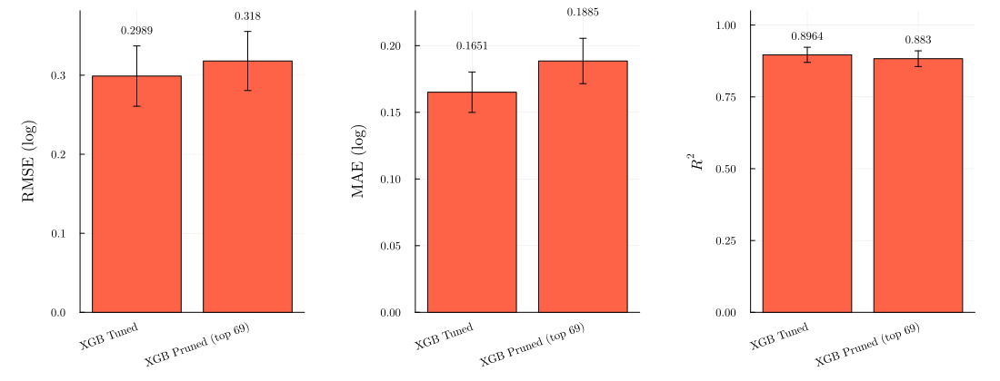

In [35]:
plot_model_comparison([winner_tuned, pruned_result])

In [ ]:
# function refit_pruned_model(X_train::Matrix{Float64}, y_train::Vector{Float64},
#                              folds::Vector, feature_cols::Vector,
#                              imp_df::DataFrame, best_n::Int,
#                              model_type::Symbol, phase2_result::ModelResult;
#                              rf_params=nothing, xgb_params=nothing,
#                              seed::Int=42)
#     with_logger(NullLogger()) do
#     top_features  = imp_df.feature[1:best_n]
#     col_idx       = [findfirst(==(f), string.(feature_cols)) for f in top_features]
#     X_pruned      = X_train[:, col_idx]

#     rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

#     for fold in folds
#         X_tr = X_pruned[fold.train, :]
#         X_vl = X_pruned[fold.val,   :]
#         y_tr = y_train[fold.train]
#         y_vl = y_train[fold.val]

#         if model_type == :rf
#             model = build_forest(y_tr, X_tr,
#                 round(Int, sqrt(best_n)),
#                 500, 0.7, rf_params.max_depth; rng=seed)
#             preds = apply_forest(model, X_vl)
#         elseif model_type == :xgb
#             model = xgboost(DMatrix(X_tr, label=y_tr);
#                 num_round=xgb_params.num_round, max_depth=xgb_params.max_depth,
#                 eta=xgb_params.eta, subsample=xgb_params.subsample,
#                 colsample_bytree=0.8, objective="reg:squarederror",
#                 seed=seed)
#             preds = predict(model, DMatrix(X_vl))
#         end

#         rmse, mae, r2 = score_predictions(y_vl, preds)
#         push!(rmse_scores, rmse)
#         push!(mae_scores,  mae)
#         push!(r2_scores,   r2)
#     end

#     prefix = model_type == :rf ? "RF" : "XGB"
#     pruned_result = ModelResult("$(prefix) Pruned (top $(best_n))",
#         mean(rmse_scores), std(rmse_scores),
#         mean(mae_scores),  std(mae_scores),
#         mean(r2_scores),   std(r2_scores))

#     @printf("\n=== Phase 3 Summary ===\n")
#     @printf("  %-30s RMSE: %.4f ± %.4f | R²: %.4f\n",
#         phase2_result.label, phase2_result.rmse, phase2_result.rmse_std, phase2_result.r2)
#     @printf("  %-30s RMSE: %.4f ± %.4f | R²: %.4f\n",
#         pruned_result.label, pruned_result.rmse, pruned_result.rmse_std, pruned_result.r2)

#     # refit final pruned model on all training data
#     println("\n  Refitting pruned model on full training set...")
#     if model_type == :rf
#         final_model = build_forest(y_train, X_pruned,
#             round(Int, sqrt(best_n)), 500, 0.7, rf_params.max_depth; rng=seed)
#     elseif model_type == :xgb
#         final_model = xgboost(DMatrix(X_pruned, label=y_train);
#             num_round=xgb_params.num_round, max_depth=xgb_params.max_depth,
#             eta=xgb_params.eta, subsample=xgb_params.subsample,
#             colsample_bytree=0.8, objective="reg:squarederror",
#             seed=seed, verbosity=0)
#     end

#     return final_model, col_idx, pruned_result
#     end
# end

# # step 4 — refit pruned model + CV score
# final_model, final_col_idx, pruned_result = refit_pruned_model(
#     X_train, y_train, folds, feature_cols, imp_df, best_n,
#     winner_type, winner_tuned;
#     rf_params=winner_params_rf, xgb_params=winner_params_xgb)

InterruptException: InterruptException:

### Compare Pruned vs Full Feature model 

In [ ]:
# step 5 — plot phase 3 comparison
# p = plot_model_comparison([winner_tuned, pruned_result])
savefig(p, "compare_tuned_vs_pruned_05-07-2026.png")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/compare_tuned_vs_pruned_05-07-2026.png"

## Phase 4 - Final Evaluation

1. Take single best model from Phase 3
2. Evaluate it ONCE on Xtest
3. Report test RMSE, MAE, R^2
4. Back-transform to predicted dollars = 10.^predictions

In [33]:
# ============================================================
# PHASE 4 — FINAL EVALUATION
# ============================================================

function evaluate_final_model(model, model_type::Symbol,
                               X_test::Matrix{Float64}, y_test::Vector{Float64},
                               feature_cols::Vector, col_idx::Vector{Int})

    # subset test set to pruned features
    X_test_pruned = X_test[:, col_idx]

    # predict on log scale
    if model_type == :rf
        log_preds = apply_forest(model, X_test_pruned)
    elseif model_type == :xgb
        log_preds = XGBoost.predict(model, DMatrix(X_test_pruned))
    end

    # metrics on log scale
    rmse, mae, r2 = score_predictions(y_test, log_preds)

    # back-transform to dollars
    pred_dollars = 10 .^ log_preds
    true_dollars = 10 .^ y_test

    # dollar-scale metrics
    dollar_residuals  = true_dollars .- pred_dollars
    dollar_rmse       = sqrt(mean(dollar_residuals .^ 2))
    dollar_mae        = mean(abs.(dollar_residuals))
    dollar_ss_res     = sum(dollar_residuals .^ 2)
    dollar_ss_tot     = sum((true_dollars .- mean(true_dollars)) .^ 2)
    dollar_r2         = 1 - dollar_ss_res / dollar_ss_tot

    # median absolute percentage error — more interpretable than RMSE for log-normal
    mape = median(abs.(dollar_residuals ./ true_dollars) .* 100)

    println("=== PHASE 4 — FINAL TEST SET EVALUATION ===")
    println("\n  Log₁₀ Scale (what the model optimized):")
    @printf("    RMSE: %.4f\n", rmse)
    @printf("    MAE:  %.4f\n", mae)
    @printf("    R²:   %.4f\n", r2)

    println("\n  Dollar Scale (back-transformed):")
    @printf("    RMSE:   \$%.2f\n",   dollar_rmse)
    @printf("    MAE:    \$%.2f\n",   dollar_mae)
    @printf("    R²:     %.4f\n",     dollar_r2)
    @printf("    MdAPE:  %.1f%%\n",   mape)

    println("\n  Interpretation:")
    @printf("    Median prediction is within %.1f%% of true value\n", mape)
    @printf("    A log RMSE of %.4f means ~%.1fx typical error in dollar terms\n",
        rmse, 10^rmse)

    # results dataframe for further analysis
    results_df = DataFrame(
        true_log       = y_test,
        pred_log       = log_preds,
        true_dollars   = true_dollars,
        pred_dollars   = pred_dollars,
        abs_pct_error  = abs.(dollar_residuals ./ true_dollars) .* 100,
        log_residual   = y_test .- log_preds
    )

    return results_df, (
        log_rmse     = rmse,
        log_mae      = mae,
        log_r2       = r2,
        dollar_rmse  = dollar_rmse,
        dollar_mae   = dollar_mae,
        dollar_r2    = dollar_r2,
        mape         = mape
    )
end


function plot_final_results(results_df::DataFrame, test_metrics)

    # 1 — predicted vs actual (log scale)
    p1 = scatter(results_df.true_log, results_df.pred_log,
        xlabel    = "actual log₁₀(award amount)",
        ylabel    = "predicted log₁₀(award amount)",
        title     = "Predicted vs Actual",
        label     = false,
        alpha     = 0.3,
        markersize = 2,
        color     = :steelblue,
        size      = (500, 450)
    )
    # perfect prediction line
    min_val = minimum(results_df.true_log)
    max_val = maximum(results_df.true_log)
    plot!(p1, [min_val, max_val], [min_val, max_val],
        label     = "perfect fit",
        color     = :red,
        linestyle = :dash,
        linewidth = 2)

    # 2 — residuals vs predicted (log scale)
    p2 = scatter(results_df.pred_log, results_df.log_residual,
        xlabel    = "predicted log₁₀(award amount)",
        ylabel    = "residual",
        title     = "Residuals vs Predicted",
        label     = false,
        alpha     = 0.3,
        markersize = 2,
        color     = :steelblue,
        size      = (500, 450)
    )
    hline!(p2, [0.0],
        color     = :red,
        linestyle = :dash,
        linewidth = 2,
        label     = "zero")

    # 3 — residual distribution
    p3 = histogram(results_df.log_residual,
        normalize  = :pdf,
        bins       = 60,
        xlabel     = "residual (log₁₀ scale)",
        ylabel     = "density",
        title      = "Residual Distribution",
        label      = false,
        color      = :steelblue,
        alpha      = 0.7,
        size       = (500, 450)
    )
    vline!(p3, [0.0],
        color     = :red,
        linestyle = :dash,
        linewidth = 2,
        label     = "zero")

    # 4 — absolute % error distribution (capped at 200% for readability)
    capped_errors = min.(results_df.abs_pct_error, 200.0)
    p4 = histogram(capped_errors,
        normalize  = :pdf,
        bins       = 50,
        xlabel     = "absolute % error (capped at 200%)",
        ylabel     = "density",
        title      = "% Error Distribution",
        label      = false,
        color      = :coral,
        alpha      = 0.7,
        size       = (500, 450)
    )
    vline!(p4, [test_metrics.mape],
        color     = :red,
        linestyle = :dash,
        linewidth = 2,
        label     = "median $(round(test_metrics.mape, digits=1))%")

    plot(p1, p2, p3, p4,
        layout = (2, 2),
        size   = (1000, 850),
        plot_title = "Final Model Evaluation — Test Set"
    )
end


# ============================================================
# RUN PHASE 4
# ============================================================

results_df, test_metrics = evaluate_final_model(
    final_model, winner_type,
    X_test, y_test,
    feature_cols, final_col_idx
)


=== PHASE 4 — FINAL TEST SET EVALUATION ===

  Log₁₀ Scale (what the model optimized):
    RMSE: 0.4930
    MAE:  0.3498
    R²:   0.7227

  Dollar Scale (back-transformed):
    RMSE:   $88845003.50
    MAE:    $2209672.47
    R²:     0.1037
    MdAPE:  54.3%

  Interpretation:
    Median prediction is within 54.3% of true value
    A log RMSE of 0.4930 means ~3.1x typical error in dollar terms


(85904×6 DataFrame
   Row │ true_log  pred_log  true_dollars    pred_dollars    abs_pct_error  lo ⋯
       │ Float64   Float32   Float64         Float32         Float64        Fl ⋯
───────┼────────────────────────────────────────────────────────────────────────
     1 │  4.0513    4.33187   11253.8         21472.0             90.7981      ⋯
     2 │  5.51286   5.60303  325729.0        400892.0             23.0753
     3 │  7.39501   6.73133       2.48318e7       5.38678e6       78.3069
     4 │  3.99922   3.98017    9982.0          9553.66             4.29112
     5 │  4.23919   3.9177    17345.6          8273.65            52.3011      ⋯
     6 │  6.92012   6.57616       8.31987e6       3.76841e6       54.7059
     7 │  5.80344   6.00955       6.35975e5       1.02223e6       60.7346
     8 │  6.10684   5.77738       1.2789e6        5.98938e5       53.1676
   ⋮   │    ⋮         ⋮            ⋮               ⋮               ⋮           ⋱
 85898 │  4.2988    3.90613   19897.5          805

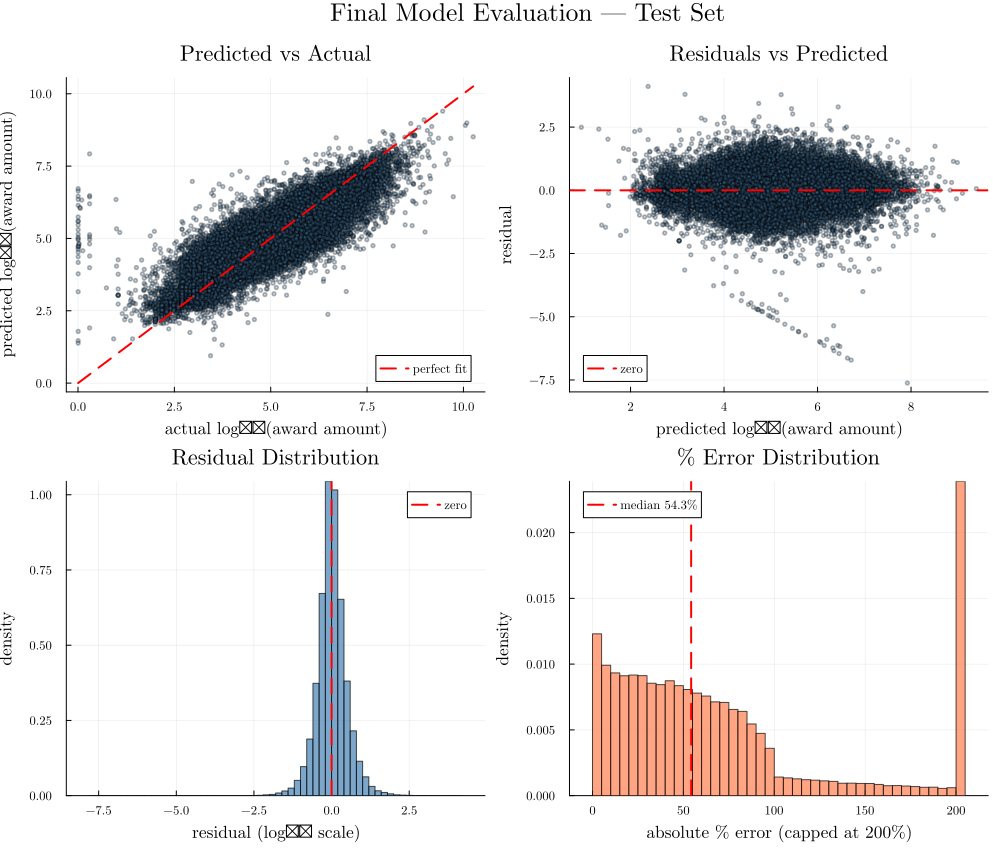

GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph missing from current font: 8320
GKS: glyph missing from current font: 8321
GKS: glyph 

In [36]:
p = plot_final_results(results_df, test_metrics)
#savefig(p, "final_evaluation_plots_using_full_model_05-07-2026-1905.png")